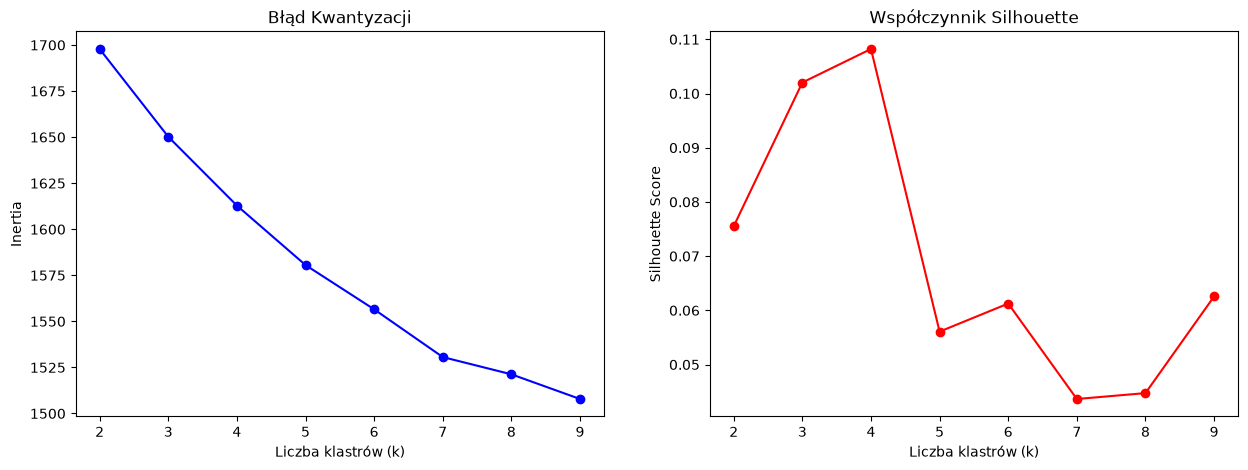

In [1]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import KernelPCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt

newsgroups_train = fetch_20newsgroups(subset='train',remove=('headers','footers','quotes'))
original_texts = newsgroups_train.data

pipeline = Pipeline([
('tfidf', TfidfVectorizer(max_features = 5000, stop_words='english')),
('pca', KernelPCA(n_components=100, random_state=42))
])
pca_matrix = pipeline.fit_transform(original_texts)

k_values = range(2,10)
inertias = []
silhouettes = []


for k in k_values:
    kmeans = KMeans(n_clusters=k,random_state=42)
    labels = kmeans.fit_predict(pca_matrix)
    
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(pca_matrix,labels))
    
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1.plot(k_values,inertias,marker='o',color='blue')
ax1.set_title("Błąd Kwantyzacji")
ax1.set_xlabel("Liczba klastrów (k)")
ax1.set_ylabel("Inertia")


ax2.plot(k_values, silhouettes, marker='o', color='red')
ax2.set_title("Współczynnik Silhouette")
ax2.set_xlabel("Liczba klastrów (k)")
ax2.set_ylabel("Silhouette Score")

plt.show()



### Metoda łokcia oznacza zauważenie na wykresie błędu kwantyzacji wyraźnego spadku nachylenia, tutaj w tym przypadku jest to k=7

### Ale na podstawie współczynnika silhoutte najlepszy wybór to k=4


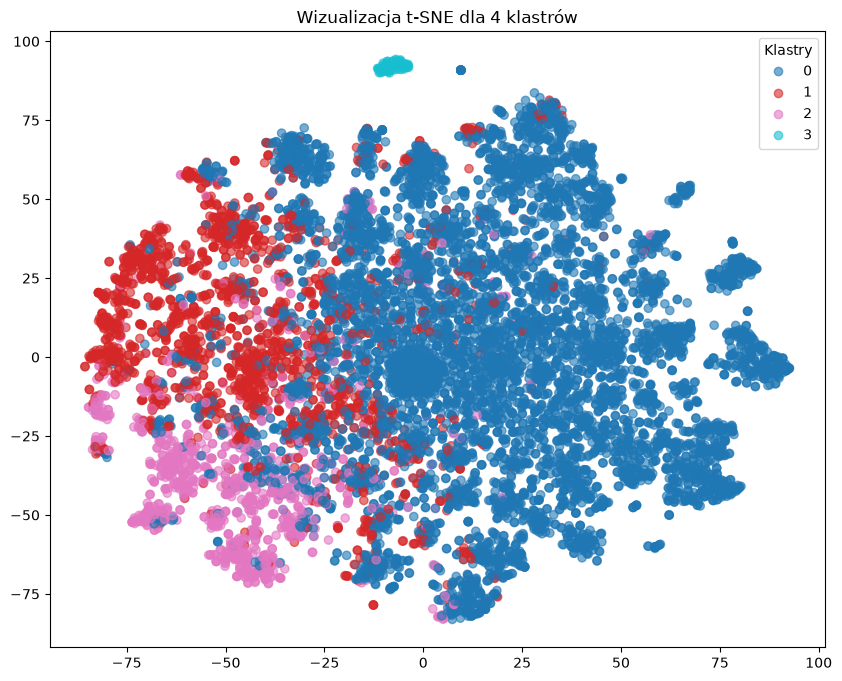

In [2]:
best_k = 4

kmeans = KMeans(n_clusters=4,random_state=42)
labels = kmeans.fit_predict(pca_matrix)

tsne = TSNE(n_components=2,random_state=42,perplexity=15)
matrix_2d = tsne.fit_transform(pca_matrix)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(matrix_2d[:, 0], matrix_2d[:, 1], c=labels, cmap='tab10', alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Klastry")
plt.title(f"Wizualizacja t-SNE dla {best_k} klastrów")
plt.show()


In [3]:
for klaster_id in range(best_k):
    print(f"\n{'='*50}")
    print(f"KLASTER {klaster_id} - Przykładowe teksty:")
    print(f"{'='*50}")
    
    # Pobieramy indeksy dokumentów, które K-Means przypisał do obecnego klastra
    indeksy_w_klastrze = np.where(labels == klaster_id)[0]
    
    # Wyświetlamy 3 przykładowe teksty, obcinając je do pierwszych 300 znaków
    for idx in indeksy_w_klastrze[:3]:
        tekst = original_texts[idx]
        print(f"-> {tekst[:300]}...\n")


KLASTER 0 - Przykładowe teksty:
-> I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I k...

-> From article <C5owCB.n3p@world.std.com>, by tombaker@world.std.com (Tom A Baker):


My understanding is that the 'expected errors' are basically
known bugs in the warning system software - things are checked
that don't have the right values in yet because they aren't
set till after launch, and suchl...

-> 




Of course.  The term must be rigidly defined in any bill.


I doubt she uses this term for that.  You are using a quote allegedly
from her, can you back it up?




I read the article as presenting first an argument about weapons of mass
destruction (as commonly understood) and then switching to...


KLASTER 1 - Przykładowe teksty:
-> A fair 